In [1]:
from requirements import *

# Extended Data Figure 3

In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## ED Figure 3a. Cell-type frequency within each sample (stacked bar, all samples)


<Figure size 1040x280 with 0 Axes>

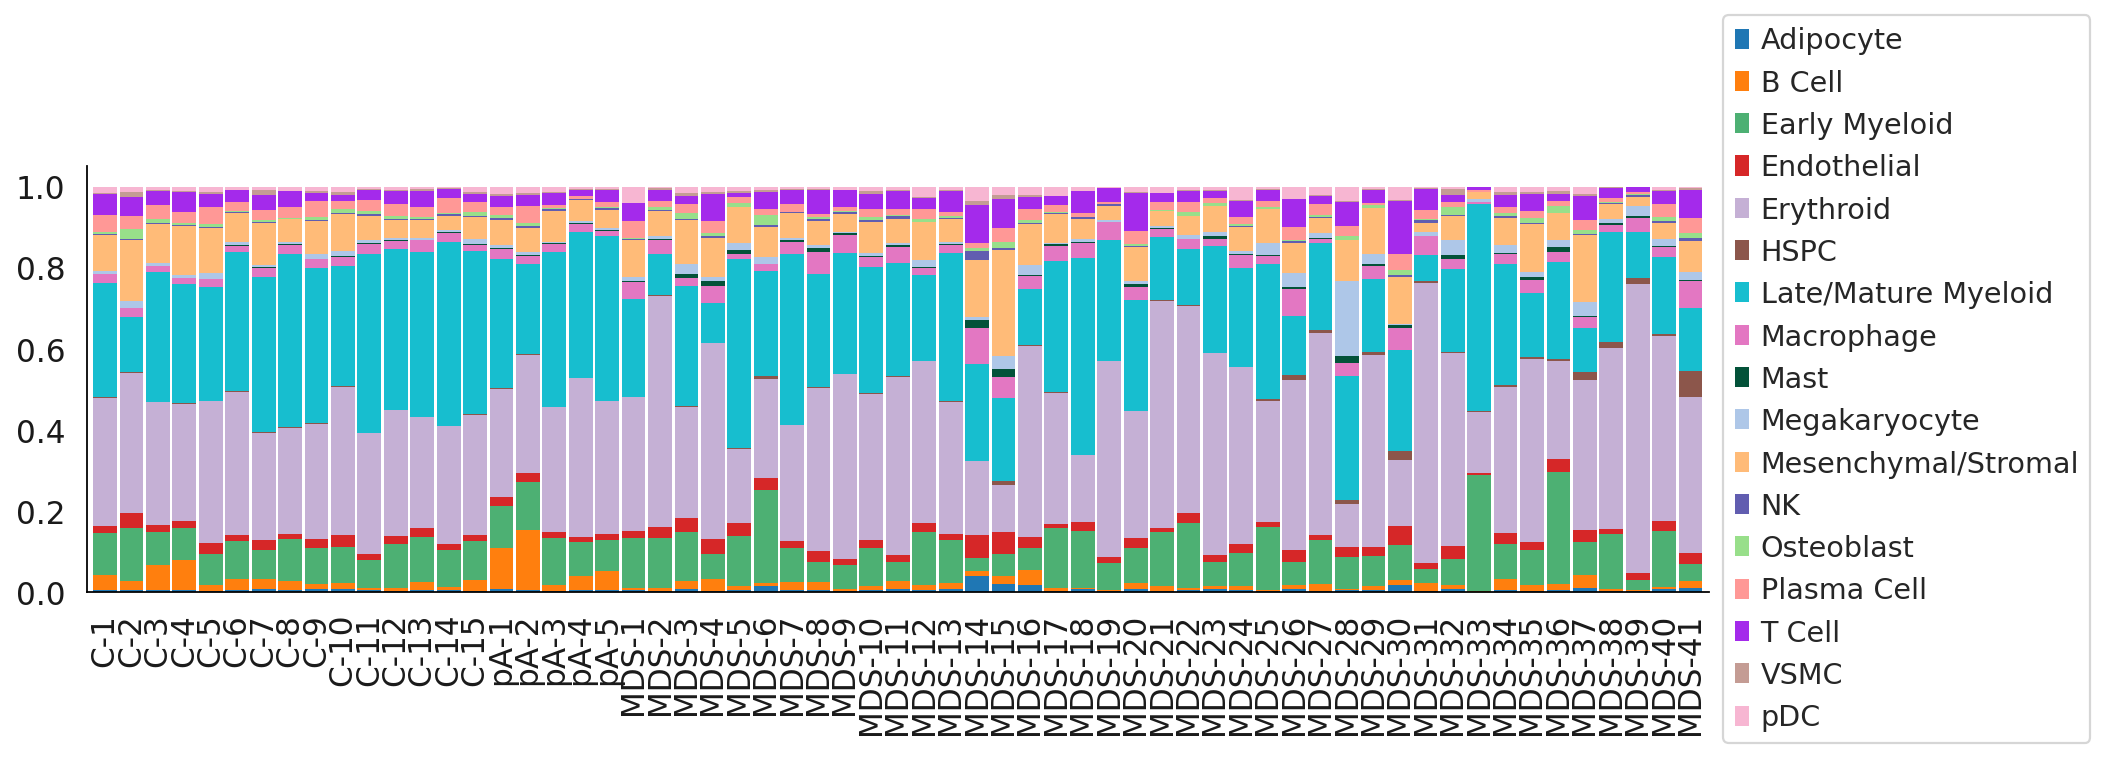

In [3]:
sc.set_figure_params(figsize=(13, 3.5))
matplotlib.rcParams['pdf.fonttype'] = 42
f = plt.figure()

df = pd.crosstab(index=adata_xenv1.obs['study_id'], columns=adata_xenv1.obs['ct_general'])
df.index = df.index.astype(str)
#df = df.sort_index()
samp_order = ['C-' + str(x) for x in range(1, 16)] + ['pA-' + str(x) for x in range(1, 6)] + ['MDS-' + str(x) for x in range(1, 42)]
df.index = pd.Categorical(df.index, categories = samp_order, ordered = True)
df = df.sort_index()
df = df.apply(lambda x: x/x.sum(), axis=1)

cmp = matplotlib.colors.ListedColormap(["#1f77b4", "#ff7f0e", "#4db073","#d62728", "#c5b0d5",'#8c564b', "#17becf", "#e377c2", "#035239", "#aec7e8", "#ffbb78",'#615db0',"#98df8a", "#ff9896","#a42aeb","#c49c94", "#f7b6d2"])
g = df.plot(kind='bar', stacked=True, width = 0.9, colormap= cmp, edgecolor= 'none')
g.spines['top'].set_visible(False)
g.spines['right'].set_visible(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()



## ED Figure 3e. PCA by cell type composition


[0.67753035 0.18660898]


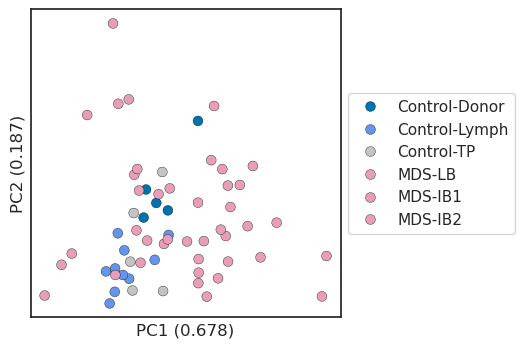

In [4]:
### PCA by cell type proportion
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.crosstab(index=adata_xenv1.obs['study_id'], columns=adata_xenv1.obs['ct_general'])
df.index = df.index.astype(str)
df = df.apply(lambda x: x/x.sum(), axis=1)


pca = PCA(n_components=2)
principalComponents = pca.fit_transform(df)
print(pca.explained_variance_ratio_)
type_map = dict(zip(adata_xenv1.obs['study_id'], adata_xenv1.obs['diagnosis']))
principalDf = pd.DataFrame(data = principalComponents, columns = ['principal component 1', 'principal component 2'])
principalDf['diagnosis'] = [type_map[x] for x in df.index]
principalDf['sample_id'] = [x for x in df.index]
plt.figure(figsize=(4, 4))
principalDf['diagnosis'] = principalDf['diagnosis'].astype('category')
principalDf['diagnosis'] = principalDf['diagnosis'].cat.reorder_categories(['Control-Donor','Control-Lymph','Control-TP', 'MDS-LB','MDS-IB1','MDS-IB2'], ordered = True)

sns.set_style("white")
ax = sns.scatterplot(data=principalDf, x="principal component 1", y="principal component 2", linewidth=0.25, s = 50, edgecolor = 'black', hue="diagnosis", palette = [ "#0072B2", "#6495ED", "#c4c4c4", "#E89EB8", "#E89EB8", "#E89EB8"])
ax.set_xlabel("PC1" + ' (' + str(round(pca.explained_variance_ratio_[0], 3)) + ')')
ax.set_ylabel("PC2" + ' (' + str(round(pca.explained_variance_ratio_[1], 3)) + ')')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.xticks([])
plt.yticks([])

plt.show()

## ED Figure 3f: see DUNE_script.ipynb